# ARIA v9.0 - The Cloud Engine

**Study area:** Xiulin / Taroko, Taiwan  
**Main event:** 2024-04-03 Hualien earthquake  
**Goal:** Use Google Earth Engine to analyze NDVI and Sentinel-1 SAR time series at cloud scale.

> Run this notebook in Google Colab or Jupyter with Earth Engine authentication enabled. Replace `PROJECT_ID` with your Google Cloud project id before running the initialization cell.

## 0. Setup

Install/import packages and initialize Earth Engine. In Colab, run the install cell first if `geemap` is missing.

In [1]:
# In Colab, uncomment this if needed.
# %pip install -q earthengine-api geemap imageio pillow

import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datetime import datetime

In [2]:
# First-time use requires authentication.
# ee.Authenticate()

PROJECT_ID = 'moonlit-mesh-479012-e0'  # TODO: replace with your Google Cloud project id

ee.Initialize(project=PROJECT_ID)
print('Earth Engine initialized')

Earth Engine initialized


In [3]:
# Xiulin / Taroko study area BBOX: [west, south, east, north]
TAROKO_BBOX = [121.34526379253053, 24.046021742135874, 121.85149217685861, 24.35767637905926]
aoi = ee.Geometry.Rectangle(TAROKO_BBOX)

Map = geemap.Map(center=[24.20, 121.60], zoom=10, basemap='HYBRID')
Map.addLayer(aoi, {'color': 'yellow'}, 'AOI: Xiulin / Taroko')
Map

Map(center=[24.2, 121.6], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

## Task 1. NDVI Time Series Analysis

Use Sentinel-2 L2A images from 2020-01-01 to 2026-03-31. Apply an SCL cloud mask, calculate NDVI, then plot monthly mean NDVI over the AOI.

In [4]:
s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterBounds(aoi)
    .filterDate('2020-01-01', '2026-03-31')
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 40)))

print('Total Sentinel-2 images:', s2.size().getInfo())

Total Sentinel-2 images: 291


In [5]:
def mask_and_ndvi(image):
    # Mask clouds/shadows using SCL and calculate NDVI.
    scl = image.select('SCL')
    good = scl.eq(4).Or(scl.eq(5)).Or(scl.eq(6)).Or(scl.eq(7))
    masked = image.updateMask(good)
    ndvi = masked.normalizedDifference(['B8', 'B4']).rename('NDVI')
    return ndvi.copyProperties(image, ['system:time_start'])

ndvi_collection = s2.map(mask_and_ndvi)
print('NDVI collection ready')

NDVI collection ready


In [ ]:
# Monthly mean NDVI over the AOI. This loop is simple and transparent for homework reporting.
months = pd.date_range('2020-01-01', '2026-03-01', freq='MS')
records = []

for start in months:
    end = start + pd.DateOffset(months=1)
    start_str = start.strftime('%Y-%m-%d')
    end_str = end.strftime('%Y-%m-%d')

    monthly_collection = ndvi_collection.filterDate(start_str, end_str)
    image_count = monthly_collection.size().getInfo()

    if image_count == 0:
        mean_ndvi = np.nan
    else:
        monthly_median = monthly_collection.median()
        result = monthly_median.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=aoi,
            scale=10,
            maxPixels=1e9,
            bestEffort=True,
        )
        value = result.get('NDVI').getInfo()
        mean_ndvi = np.nan if value is None else value

    records.append({'month': start, 'image_count': image_count, 'mean_ndvi': mean_ndvi})
    print(start.strftime('%Y-%m'), image_count, mean_ndvi)

ndvi_monthly = pd.DataFrame(records)
ndvi_monthly.head()

2020-01 8 0.46046069808283585
2020-02 4 0.4609886268749004
2020-03 5 0.43008401474075153
2020-04 2 0.4992586871154388
2020-05 4 0.438343488939398
2020-06 5 0.5502039332569464
2020-07 5 0.5292806942020246
2020-08 4 0.5121558854982048
2020-09 5 0.49268898372237935
2020-10 3 0.481273626737107
2020-11 5 0.49913966452578545
2020-12 2 0.3454894524922552
2021-01 6 0.49136351728557975
2021-02 6 0.4271808714091131
2021-03 6 0.47875304222877396
2021-04 4 0.4706217656748067
2021-05 5 0.5244260080307487
2021-06 2 0.6667027393864452
2021-07 6 0.5335764212036651
2021-08 3 0.4869719795269736
2021-09 10 0.466296770736305
2021-10 3 0.3521494498026309
2021-11 8 0.42880907827395676
2021-12 4 0.4663908442836192
2022-01 0 nan
2022-02 0 nan
2022-03 4 0.4779890070091942
2022-04 3 0.4808069304616142
2022-05 1 0.626571403442311
2022-06 2 0.5316298965794916
2022-07 7 0.5531367317849231
2022-08 5 0.531928780525351
2022-09 5 0.5187371292938716
2022-10 4 0.512712210664757
2022-11 2 0.32131818183231686
2022-12 3 0.

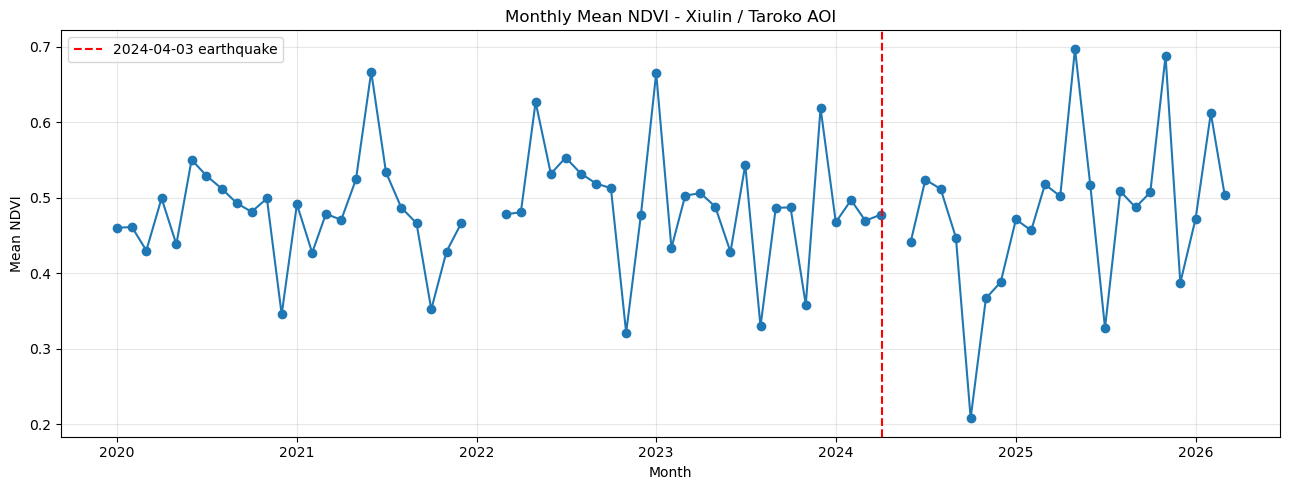

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(ndvi_monthly['month'], ndvi_monthly['mean_ndvi'], marker='o', linewidth=1.5)
ax.axvline(pd.Timestamp('2024-04-03'), color='red', linestyle='--', label='2024-04-03 earthquake')
ax.set_title('Monthly Mean NDVI - Xiulin / Taroko AOI')
ax.set_xlabel('Month')
ax.set_ylabel('Mean NDVI')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig('output/monthly_mean_ndvi.png', dpi=300)
plt.show()

### Task 1 Analysis
---
- Seasonal pattern:
從 2020 到 2026 年的 monthly mean NDVI 來看，研究區有一定程度的季節性變化，但規律性不算非常明顯。NDVI 大多落在 0.4 到 0.6 之間，部分月份會突然升高或降低，可能與山區植被季節變化、降雨、雲量與地形陰影有關。

- Earthquake effect:
2024/04/03 地震後，NDVI 沒有在地震當月立刻出現明顯整體下降，但在 2024 年後段可以看到一個非常低的 NDVI 值，約降到 0.2 左右。這可能代表地震後崩塌、裸露地表增加或植被受損，但也需要搭配 Task 2 的前後期 NDVI composite 與 delta NDVI map 進一步確認。

- Missing data months and possible reasons:
圖上有些月份沒有點或資料較不連續，代表該月可能缺少有效 NDVI 值。主要原因可能是太魯閣 / 秀林屬於山區，雲量高、地形陰影明顯，加上 Sentinel-2 影像經過 SCL 雲遮罩後，可用像素變少，導致某些月份資料不足或平均值不穩定。

## Task 2. Pre/Post Earthquake Median Composite

Create three NDVI median composites and compare vegetation change among periods.

In [ ]:
pre_eq = ndvi_collection.filterDate('2023-01-01', '2024-03-31').median().rename('NDVI').clip(aoi)
post_eq = ndvi_collection.filterDate('2024-04-01', '2024-09-30').median().rename('NDVI').clip(aoi)
post_dam = ndvi_collection.filterDate('2025-10-01', '2026-03-31').median().rename('NDVI').clip(aoi)

delta_eq = post_eq.subtract(pre_eq).rename('delta_NDVI')
delta_dam = post_dam.subtract(post_eq).rename('delta_NDVI_dam')
delta_total = post_dam.subtract(pre_eq).rename('delta_NDVI_total')

print('NDVI composites and delta maps ready')

NDVI composites and delta maps ready


In [ ]:
ndvi_vis = {'min': 0, 'max': 0.85, 'palette': ['brown', 'yellow', 'green', 'darkgreen']}
delta_vis = {'min': -0.4, 'max': 0.4, 'palette': ['red', 'white', 'blue']}

Map2 = geemap.Map(center=[24.20, 121.60], zoom=10, basemap='HYBRID')
Map2.addLayer(aoi, {'color': 'yellow'}, 'AOI')
Map2.addLayer(pre_eq, ndvi_vis, 'Pre-earthquake NDVI: 2023-01 to 2024-03')
Map2.addLayer(post_eq, ndvi_vis, 'Post-earthquake NDVI: 2024-04 to 2024-09')
Map2.addLayer(post_dam, ndvi_vis, 'Post-dam NDVI: 2025-10 to 2026-03')
Map2.addLayer(delta_eq, delta_vis, 'Delta NDVI: post_eq - pre_eq')
Map2.addLayer(delta_dam, delta_vis, 'Delta NDVI: post_dam - post_eq')
Map2.addLayer(delta_total, delta_vis, 'Delta NDVI: post_dam - pre_eq')
Map2

Map(center=[24.2, 121.6], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

In [ ]:
def damaged_area_ha(delta_image, threshold=-0.15, name='delta'):
    damaged = delta_image.lt(threshold)
    area_image = ee.Image.pixelArea().divide(10000).updateMask(damaged)
    area = area_image.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=aoi,
        scale=10,
        maxPixels=1e9,
        bestEffort=True,
    ).get('area')
    return {'phase': name, 'threshold': threshold, 'area_ha': area.getInfo()}

area_results = pd.DataFrame([
    damaged_area_ha(delta_eq, -0.15, 'Earthquake phase: post_eq - pre_eq'),
    damaged_area_ha(delta_dam, -0.15, 'Later phase: post_dam - post_eq'),
    damaged_area_ha(delta_total, -0.15, 'Total phase: post_dam - pre_eq'),
])

area_results

,phase,threshold,area_ha
0,Earthquake phase: post_eq - pre_eq,-0.15,7740.145333
1,Later phase: post_dam - post_eq,-0.15,6257.677281
2,Total phase: post_dam - pre_eq,-0.15,6839.039621


### Task 2 Analysis
---
- Earthquake damage areas:
地震前後階段（post_eq - pre_eq）中，delta_NDVI < -0.15 的面積約為 7740.15 公頃，是三個階段中最大的下降面積。這表示 2024/04/03 地震後，研究區內有相當範圍出現明顯 NDVI 下降，可能與地震造成的崩塌、植被破壞、裸露地表增加或坡面擾動有關。

- Later landslide-dam or post-event impact:
後續階段（post_dam - post_eq）中，delta_NDVI < -0.15 的面積約為 6257.68 公頃，表示地震後到 2025/2026 期間仍有不少區域出現 NDVI 下降。這可能代表後續崩塌、堰塞湖相關影響、河道或坡地持續變動，也可能包含季節差異與山區影像品質造成的影響。

- Possible vegetation recovery:
總變化階段（post_dam - pre_eq）中，delta_NDVI < -0.15 的面積約為 6839.04 公頃，低於地震前後短期階段的 7740.15 公頃。這表示部分地震後 NDVI 下降的區域，在後續期間可能有一定程度的植被恢復。不過仍有超過 6800 公頃維持明顯下降，代表部分區域可能尚未完全恢復，或仍受到後續地表擾動影響。

- Comparison with W9 two-scene change detection:
W9 使用兩張單一日期影像做 NDVI 變遷偵測，結果容易受到雲、陰影、影像日期與季節差異影響。W13 使用多張影像的 median composite，可以降低單張影像異常值造成的誤判，讓地震前後與後續階段的變化更穩定。三階段比較也比兩期比較更完整，能分辨地震立即影響、後續事件影響，以及可能的植被恢復。

## Task 3. Sentinel-1 SAR Time Series

Use Sentinel-1 GRD VV images to inspect radar backscatter changes before and after the earthquake.

In [ ]:
s1 = (ee.ImageCollection('COPERNICUS/S1_GRD')
    .filterBounds(aoi)
    .filterDate('2022-01-01', '2026-03-31')
    .filter(ee.Filter.eq('instrumentMode', 'IW'))
    .filter(ee.Filter.eq('orbitProperties_pass', 'DESCENDING'))
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
    .select('VV'))

print('Total Sentinel-1 images:', s1.size().getInfo())

Total Sentinel-1 images: 146


In [ ]:
def image_to_vv_feature(image):
    mean_vv = image.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=aoi,
        scale=10,
        maxPixels=1e9,
        bestEffort=True,
    ).get('VV')
    return ee.Feature(None, {
        'date': ee.Date(image.get('system:time_start')).format('YYYY-MM-dd'),
        'mean_vv': mean_vv,
    })

vv_fc = ee.FeatureCollection(s1.map(image_to_vv_feature))
vv_df = geemap.ee_to_df(vv_fc)
vv_df['date'] = pd.to_datetime(vv_df['date'])
vv_df = vv_df.sort_values('date')
vv_df.head()

,date,mean_vv
0,2022-01-03,-10.287202
1,2022-02-08,-10.463258
2,2022-07-26,-11.613096
3,2022-08-07,-10.212450
4,2022-08-19,-11.087798


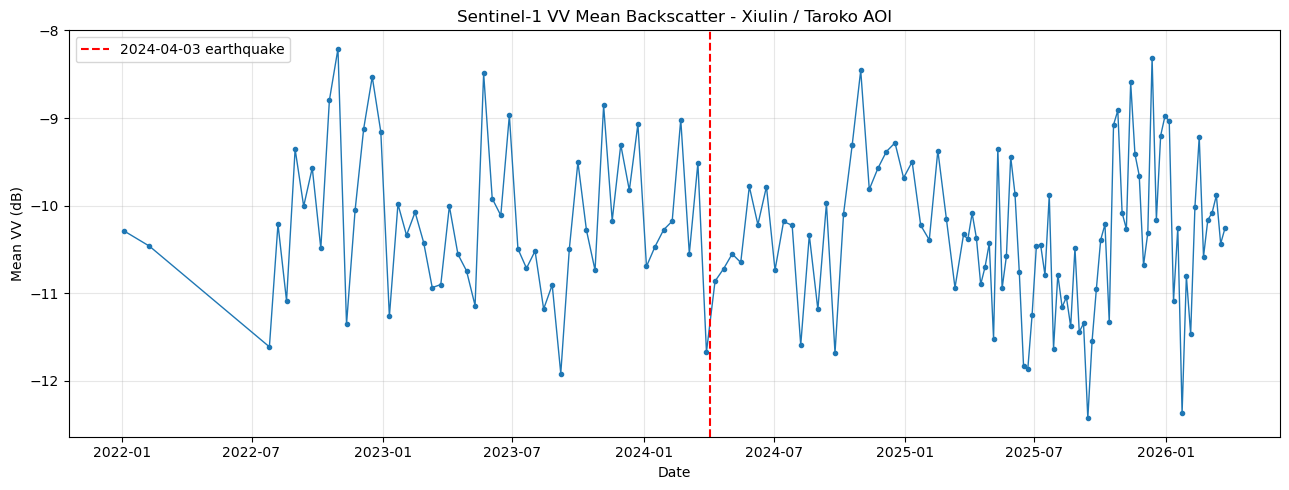

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(vv_df['date'], vv_df['mean_vv'], marker='.', linewidth=1)
ax.axvline(pd.Timestamp('2024-04-03'), color='red', linestyle='--', label='2024-04-03 earthquake')
ax.set_title('Sentinel-1 VV Mean Backscatter - Xiulin / Taroko AOI')
ax.set_xlabel('Date')
ax.set_ylabel('Mean VV (dB)')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig('output/sentinel1_vv_time_series.png', dpi=300)
plt.show()

In [ ]:
pre_vv = s1.filterDate('2023-01-01', '2024-03-31').median().rename('VV').clip(aoi)
post_vv = s1.filterDate('2024-04-01', '2026-03-31').median().rename('VV').clip(aoi)
delta_vv = post_vv.subtract(pre_vv).rename('delta_VV').clip(aoi)

vv_vis = {'min': -25, 'max': 0}
delta_vv_vis = {'min': -5, 'max': 5, 'palette': ['purple', 'white', 'orange']}

Map3 = geemap.Map(center=[24.20, 121.60], zoom=10, basemap='HYBRID')
Map3.addLayer(pre_vv, vv_vis, 'Pre-earthquake VV')
Map3.addLayer(post_vv, vv_vis, 'Post-earthquake VV')
Map3.addLayer(delta_vv, delta_vv_vis, 'Delta VV: post - pre')
Map3.addLayer(aoi, {'color': 'yellow'}, 'AOI')
Map3

Map(center=[24.2, 121.6], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

In [ ]:
# High-confidence change mask: vegetation loss plus strong SAR change.
high_conf_change = delta_eq.lt(-0.15).And(delta_vv.abs().gt(2)).rename('high_conf_change').clip(aoi)

Map4 = geemap.Map(center=[24.20, 121.60], zoom=10, basemap='HYBRID')
Map4.addLayer(delta_eq, delta_vis, 'Delta NDVI')
Map4.addLayer(delta_vv, delta_vv_vis, 'Delta VV')
Map4.addLayer(high_conf_change.selfMask(), {'palette': ['cyan']}, 'NDVI loss and |Delta VV| > 2 dB')
Map4.addLayer(aoi, {'color': 'yellow'}, 'AOI')
Map4

Map(center=[24.2, 121.6], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

### Task 3 Analysis
---
- VV time series pattern:
Sentinel-1 VV time series 顯示研究區的後向散射值隨時間有明顯波動，但不像 NDVI 一樣直接反映植被綠度。VV 會受到地表粗糙度、坡向、含水量、裸露地表與植被結構影響，因此山區資料本身變異較大。地震後若出現局部 VV 增加或下降，可能代表崩塌地、裸露坡面或地表散射條件改變。

- Delta VV map interpretation:
Delta VV map 代表地震後 VV median composite 減去地震前 VV median composite。正值區域表示地震後 VV 增加，可能與裸露地、崩塌堆積物、粗糙地表增加有關；負值區域表示 VV 下降，可能與地表變平滑、含水狀態改變、植被或陰影效應有關。由於 SAR 對地形非常敏感，山區的 VV 變化需要搭配地形與 NDVI 變化一起解讀。

- Correlation between NDVI loss and SAR change:
NDVI 下降區若同時出現明顯 VV 變化，例如 |Delta VV| > 2 dB，代表該區域同時被 optical 與 SAR 資料偵測到變化，可信度較高。這些區域可能是地震後崩塌、裸露地表或坡面擾動的位置。若只有 NDVI 下降但 SAR 沒有明顯變化，可能是雲影、季節性植被變化或較小尺度的植被損失；若 SAR 有變化但 NDVI 不明顯，則可能是地表粗糙度或含水量改變，而不一定是植被破壞。

## Task 4. Export GeoTIFF + Integration Summary

Export at least two GeoTIFF products to Google Drive. Include screenshots of the Drive files in your final submission.

In [ ]:
# Export product 1: post-earthquake NDVI composite.
task_post_eq = ee.batch.Export.image.toDrive(
    image=post_eq,
    description='taroko_ndvi_post_eq_2024',
    folder='GEE_Exports',
    region=aoi,
    scale=10,
    crs='EPSG:32651',
    maxPixels=1e9,
)

task_post_eq.start()
print(task_post_eq.status())

{'state': 'READY', 'description': 'taroko_ndvi_post_eq_2024', 'priority': 100, 'creation_timestamp_ms': 1779698951355, 'update_timestamp_ms': 1779698951355, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'OCJBXPNL5ZIYJ3ZQHQLUYBWG', 'name': 'projects/moonlit-mesh-479012-e0/operations/OCJBXPNL5ZIYJ3ZQHQLUYBWG'}


In [ ]:
# Export product 2: earthquake delta NDVI map.
task_delta_eq = ee.batch.Export.image.toDrive(
    image=delta_eq,
    description='taroko_delta_ndvi_eq_2024',
    folder='GEE_Exports',
    region=aoi,
    scale=10,
    crs='EPSG:32651',
    maxPixels=1e9,
)

# Uncomment to start the export.
task_delta_eq.start()
print(task_delta_eq.status())

{'state': 'READY', 'description': 'taroko_delta_ndvi_eq_2024', 'priority': 100, 'creation_timestamp_ms': 1779698440691, 'update_timestamp_ms': 1779698440691, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'JWLUPV6QO7WHKJGOZKHTSPJ4', 'name': 'projects/moonlit-mesh-479012-e0/operations/JWLUPV6QO7WHKJGOZKHTSPJ4'}


### Integration Summary Report Draft

Write 300-500 words here.

**Data scale comparison:**  
Sentinel-2 images processed: `fill in after running Task 1`. Sentinel-1 images processed: `fill in after running Task 3`. Compared with local downloading and processing, GEE reduced the need to manually store and preprocess many large scenes.

**Key findings:**  
Describe the observed seasonal NDVI pattern, the earthquake-related NDVI changes, and whether SAR backscatter changes support the NDVI interpretation.

**Cross-week integration:**  
GEE time series improves W8 single-scene NDVI by showing temporal context. Median composite improves W9 two-scene change detection by reducing cloud and scene-specific noise. Sentinel-1 time series extends W10 SAR analysis from a snapshot to a multi-date interpretation. The exported GeoTIFFs could be used in W12 Random Forest classification as additional features or validation layers.

**Limitations:**  
Discuss limitations such as reduced control over low-level preprocessing, dependency on GEE availability, export quotas, and cases where local STAC + Python workflows are preferable.

## Bonus 2. Optional NDVI Time-Lapse GIF

This section is optional. It creates a half-year NDVI animation from thumbnail images.

In [ ]:
# Optional bonus section.
import io
import requests
import imageio
from PIL import Image, ImageDraw
periods = [
    ('2020-01', '2020-06'), ('2020-07', '2020-12'),
   ('2021-01', '2021-06'), ('2021-07', '2021-12'),
     ('2022-01', '2022-06'), ('2022-07', '2022-12'),
     ('2023-01', '2023-06'), ('2023-07', '2023-12'),
     ('2024-01', '2024-03'), ('2024-04', '2024-09'),
     ('2024-10', '2025-03'), ('2025-04', '2025-09'),
     ('2025-10', '2026-03'),
 ]

frames = []
ndvi_palette = ['brown', 'yellow', 'green', 'darkgreen']

for start, end in periods:
    composite = ndvi_collection.filterDate(f'{start}-01', f'{end}-28').median()
    thumb_url = composite.getThumbURL({
        'region': aoi,
        'dimensions': 512,
        'min': 0,
        'max': 0.8,
        'palette': ndvi_palette,
    })
    response = requests.get(thumb_url)
    img = Image.open(io.BytesIO(response.content)).convert('RGB')
    draw = ImageDraw.Draw(img)
    draw.rectangle((0, 0, 260, 32), fill=(255, 255, 255))
    draw.text((10, 8), f'{start} to {end}', fill=(0, 0, 0))
    frames.append(img)
imageio.mimsave('output/taroko_ndvi_timelapse.gif', [np.array(f) for f in frames], duration=0.8, loop=0)

brief